In [1]:
import os
import ast
import requests
from google.adk import Agent
from google.adk.agents.callback_context import CallbackContext
from google.adk.models.llm_request import LlmRequest
from google.adk.models.llm_response import LlmResponse
from google.adk.agents import LlmAgent
from google.adk.artifacts import InMemoryArtifactService
from google.adk.agents import SequentialAgent
from typing import Optional
import pandas as pd
from IPython.display import display, Image
import matplotlib.pyplot as plt
import requests
from google.adk.tools import ToolContext
from bs4 import BeautifulSoup
import time
from difflib import get_close_matches
from google.cloud import modelarmor_v1
from google.api_core.client_options import ClientOptions
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai import types
from google import genai

PROJECT_ID = "qwiklabs-gcp-01-4295d9eedc89"
LOCATION = "global"
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "TRUE"
os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_CLOUD_LOCATION"] = LOCATION


MODEL_ARMOR_LOCATION = "us-central1"
MODEL_ARMOR_TEMPLATE_ID = "challenge2v2"

template_name = (
    f"projects/{PROJECT_ID}/"
    f"locations/{MODEL_ARMOR_LOCATION}/"
    f"templates/{MODEL_ARMOR_TEMPLATE_ID}"
)

armor_client = modelarmor_v1.ModelArmorClient(
    transport="rest",
    client_options=ClientOptions(
        api_endpoint=(
            f"modelarmor.{MODEL_ARMOR_LOCATION}.rep.googleapis.com"
        )
    )
)




---

**SEC DATA AGENT**

In [2]:
SEC_HEADERS = {
    "User-Agent": "ADK Training Demo contact testforgoogleadkclass@gmail.com",
    "Accept-Encoding": "gzip, deflate",
}
headers=SEC_HEADERS

In [3]:
def retrieve_filing_text(filing):
    response = requests.get(
        filing["url"],
        headers=SEC_HEADERS,
        timeout=30
    )
    response.raise_for_status()

    soup = BeautifulSoup(response.content, "html.parser")

    for element in soup(["script", "style"]):
        element.decompose()

    text = soup.get_text(separator="\n", strip=True)

    return {
        **filing,
        "text": text,
        "character_count": len(text),
        "word_count": len(text.split())
    }

In [4]:
def get_recent_sec_filings(cik: str, tool_context: ToolContext) -> dict:
    """Retrieve the five most recent SEC filings for Apple Inc.

    Returns:
        A dictionary containing the company name, CIK,
        and five SEC filings with their metadata and text.
    """
    cik = str(cik).zfill(10)


    url = f"https://data.sec.gov/submissions/CIK{cik}.json"

    response = requests.get(
        url,
        headers=SEC_HEADERS,
        timeout=30
    )
    response.raise_for_status()

    data = response.json()
    recent = data["filings"]["recent"]

    results = []

    for i in range(min(5, len(recent["form"]))):
        accession = recent["accessionNumber"][i].replace("-", "")

        filing = {
            "form": recent["form"][i],
            "filing_date": recent["filingDate"][i],
            "accession_number": recent["accessionNumber"][i],
            "primary_document": recent["primaryDocument"][i],
            "url": (
                f"https://www.sec.gov/Archives/edgar/data/"
                f"{int(cik)}/{accession}/"
                f"{recent['primaryDocument'][i]}"
            ),
        }

        results.append(retrieve_filing_text(filing))
        time.sleep(0.2)

    tool_context.state["financial_filings"] = {
        "company": data["name"],
        "cik": cik,
        "filings": results
    }

    return {
        "status": "success",
        "company": data["name"],
        "filing_count": len(results),
        "filings": [
            {
                "form": f["form"],
                "filing_date": f["filing_date"],
                "word_count": f["word_count"],
                "url": f["url"]
            }
            for f in results
        ]
    }

In [5]:
def find_company(query: str) -> dict:
    """Find publicly traded companies by ticker or company name.

    Args:
        query: A ticker symbol or company name, including approximate names.

    Returns:
        Candidate companies with their names, tickers, and SEC CIKs.
    """
    url = "https://www.sec.gov/files/company_tickers.json"

    response = requests.get(
        url,
        headers=headers,
        timeout=30
    )
    response.raise_for_status()

    companies = list(response.json().values())
    query = query.strip().upper()

    # First try an exact ticker match.
    ticker_matches = [
        company for company in companies
        if company["ticker"].upper() == query
    ]

    if ticker_matches:
        matches = ticker_matches
    else:
        # Search for names containing the query.
        matches = [
            company for company in companies
            if query in company["title"].upper()
        ]

        # If nothing matches, try approximate names.
        if not matches:
            names = [c["title"] for c in companies]
            close_names = get_close_matches(
                query,
                names,
                n=5,
                cutoff=0.5
            )
            matches = [
                c for c in companies
                if c["title"] in close_names
            ]

    return {
        "query": query,
        "matches": [
            {
                "company": c["title"],
                "ticker": c["ticker"],
                "cik": str(c["cik_str"]).zfill(10)
            }
            for c in matches[:5]
        ]
    }

In [6]:
sec_data_agent = LlmAgent(
    name="SECDataAgent",
    model="gemini-3.6-flash",
    description="Finds companies and retrieves SEC EDGAR filings.",
    instruction="""
    You are an SEC filings retrieval specialist.

    Your responsibility is to retrieve the five most recent
    SEC filings for the company requested by the user.

    Follow these steps:
    1. Identify the company or ticker mentioned by the user.
    2. Call find_company to identify matching companies.
    3. Select the correct company and its CIK.
    4. If the company is ambiguous, ask for clarification.
    5. Call get_recent_sec_filings with the selected CIK.
    6. Confirm which company's filings were retrieved.

    Always use the tools. Never invent company CIKs
    or SEC filing information.

    Do not analyze or summarize the filing contents.
    That is the responsibility of another agent.
    """,
    tools=[
        find_company,
        get_recent_sec_filings
    ]
)

**FINANCIAL ANALYST AGENT**

______________________________________________________________________________________

In [7]:
def read_filings(tool_context: ToolContext) -> dict:
    """Read the five SEC filings stored in session state.

    Returns the company name and filing documents for analysis.
    """
    data = tool_context.state.get("financial_filings")

    if not data:
        return {"error": "No SEC filings found in session state."}

    return {
        "company": data["company"],
        "filings": [
            {
                "form": filing["form"],
                "filing_date": filing["filing_date"],
                "url": filing["url"],
                "text": filing["text"][:12000]
            }
            for filing in data["filings"]
        ]
    }

In [8]:
financial_analyst = LlmAgent(
    name="FinancialAnalyst",
    model="gemini-3.6-flash",
    description="Analyzes SEC filings and identifies key insights.",
    instruction="""
    You are an equity research analyst specializing in SEC filings.

    Your job is to analyze the five most recent SEC filings
    retrieved by the previous agent.

    First, call read_filings to access the documents.

    Produce a structured report containing:

    1. EXECUTIVE SUMMARY
       Summarize the most important findings in 3-5 sentences.

    2. KEY DEVELOPMENTS
       Identify significant disclosures, insider transactions,
       financial events, or business developments.

    3. RISKS AND CONCERNS
       Highlight potential risks or concerning disclosures.

    4. NOTABLE FIGURES
       Extract important financial figures or transaction values,
       when available.

    5. TOP 3 TAKEAWAYS
       Identify three insights suitable for an infographic.

    For each significant claim, identify the relevant
    filing type, date, and source URL.

    Do not invent information.
    Do not assume a filing contains financial statements.
    If the filings are primarily insider ownership reports,
    focus on those disclosures instead.

    Clearly distinguish reported facts from interpretation.
    """,
    tools=[read_filings],
    output_key="financial_analysis"
)



---
**Image Generation Agent**


In [9]:
def read_analysis_context(tool_context: ToolContext) -> dict:
    """Read the retrieved SEC filing context and analysis from session state."""
    filings_data = tool_context.state.get("financial_filings")
    analysis = tool_context.state.get("financial_analysis")

    if not filings_data:
        return {"error": "No filing data found in session state."}

    if not analysis:
        return {"error": "No financial analysis found in session state."}

    return {
        "company": filings_data["company"],
        "cik": filings_data["cik"],
        "filings": [
            {
                "form": filing["form"],
                "filing_date": filing["filing_date"],
                "url": filing["url"]
            }
            for filing in filings_data["filings"]
        ],
        "analysis": analysis
    }

In [10]:
image_client = genai.Client()

async def generate_infographic(
    prompt: str,
    tool_context: ToolContext
) -> dict:
    """Generate a financial infographic using Nano Banana.

    Args:
        prompt: Detailed visual instructions grounded in SEC analysis.

    Returns:
        Image generation status and saved artifact filename.
    """

    response = await image_client.aio.models.generate_content(
        model="gemini-2.5-flash-image",
        contents=prompt,
        config=types.GenerateContentConfig(
            response_modalities=["TEXT", "IMAGE"],
            image_config=types.ImageConfig(
                aspect_ratio="16:9"
            )
        )
    )

    for part in response.candidates[0].content.parts:
        if part.inline_data:
            image_bytes = part.inline_data.data
            mime_type = part.inline_data.mime_type or "image/png"

            artifact = types.Part.from_bytes(
                data=image_bytes,
                mime_type=mime_type
            )

            filename = "sec_infographic.png"

            version = await tool_context.save_artifact(
                filename=filename,
                artifact=artifact
            )

            tool_context.state["infographic_filename"] = filename

            return {
                "status": "success",
                "filename": filename,
                "artifact_version": version
            }

    return {
        "status": "error",
        "message": "Nano Banana returned no image."
    }

In [11]:
visualization_agent = LlmAgent(
    name="VisualizationAgent",
    model="gemini-2.5-flash",
    description="Generates SEC financial intelligence infographics.",
    instruction="""
    You are a professional financial infographic designer.

    Here is the financial analysis from the previous agent:

    {financial_analysis}

    Your job is to produce an actual infographic.

    1. Read the financial analysis.
    2. Identify the three most important insights.
    3. Write a detailed visual prompt containing:
       - Company name and headline
       - Three key findings
       - Relevant financial or transaction figures
       - A professional 16:9 infographic layout
       - Clear typography and modern financial design
    4. Call generate_infographic with your prompt.
    5. Report the generated image's filename.

    Do not invent data.
    Do not return only a prompt.
    You must call generate_infographic.
    """,
    tools=[generate_infographic]
)



---
**Sequential Agent**


In [12]:
root_agent = SequentialAgent(
    name="SECAnalysisPipeline",
    description=(
        "Retrieves the five latest SEC filings, analyzes them, "
        "and generates a financial intelligence infographic."
    ),
    sub_agents=[
        sec_data_agent,
        financial_analyst,
        visualization_agent
    ]
)

/tmp/ipykernel_80678/3795658676.py:1: DeprecationWarning: SequentialAgent is deprecated in favor of Workflow and will be removed in a future version. Workflow cannot yet be used as an LlmAgent sub-agent.
  root_agent = SequentialAgent(


In [13]:
APP_NAME = "sec_analysis"
USER_ID = "workshop_user"
SESSION_ID = "test_001"

session_service = InMemorySessionService()
artifact_service = InMemoryArtifactService()

await session_service.create_session(
    app_name=APP_NAME,
    user_id=USER_ID,
    session_id=SESSION_ID
)


pipeline_runner = Runner(
    agent=root_agent,
    app_name=APP_NAME,
    session_service=session_service,
    artifact_service=artifact_service
)

In [14]:
SESSION_ID = "final_pipeline_test"

await session_service.create_session(
    app_name=APP_NAME,
    user_id=USER_ID,
    session_id=SESSION_ID
)

message = types.Content(
    role="user",
    parts=[
        types.Part(
            text="Analyze the five latest SEC filings for Google and generate an infographic."
        )
    ]
)

async for event in pipeline_runner.run_async(
    user_id=USER_ID,
    session_id=SESSION_ID,
    new_message=message
):
    if event.get_function_calls():
        for call in event.get_function_calls():
            print(f"[{event.author}] Tool: {call.name}")

    if event.is_final_response() and event.content:
        for part in event.content.parts:
            if part.text:
                print(f"\n[{event.author}]\n{part.text}")

/usr/local/lib/python3.12/dist-packages/google/adk/models/llm_request.py:306: UserWarning: [EXPERIMENTAL] feature FeatureName.JSON_SCHEMA_FOR_FUNC_DECL is enabled.
  declaration = tool._get_declaration()


[SECDataAgent] Tool: find_company
[SECDataAgent] Tool: find_company
[SECDataAgent] Tool: get_recent_sec_filings

[SECDataAgent]
I have retrieved the five most recent SEC filings for **Alphabet Inc. (Google)** (CIK: `0001652044`).

Here are the details of the retrieved filings:

1. **Form 4** (Statement of Changes in Beneficial Ownership)
   - **Filing Date:** October 2, 2026
   - **URL:** [View Filing](https://www.sec.gov/Archives/edgar/data/1652044/000119312526412669/xslF345X06/ownership.xml)

2. **Form 144** (Notice of Proposed Sale of Securities)
   - **Filing Date:** September 30, 2026
   - **URL:** [View Filing](https://www.sec.gov/Archives/edgar/data/1652044/000192109426001058/xsl144X01/primary_doc.xml)

3. **Form 4** (Statement of Changes in Beneficial Ownership)
   - **Filing Date:** September 29, 2026
   - **URL:** [View Filing](https://www.sec.gov/Archives/edgar/data/1652044/000119312526408019/xslF345X06/ownership.xml)

4. **Form 4** (Statement of Changes in Beneficial Owners

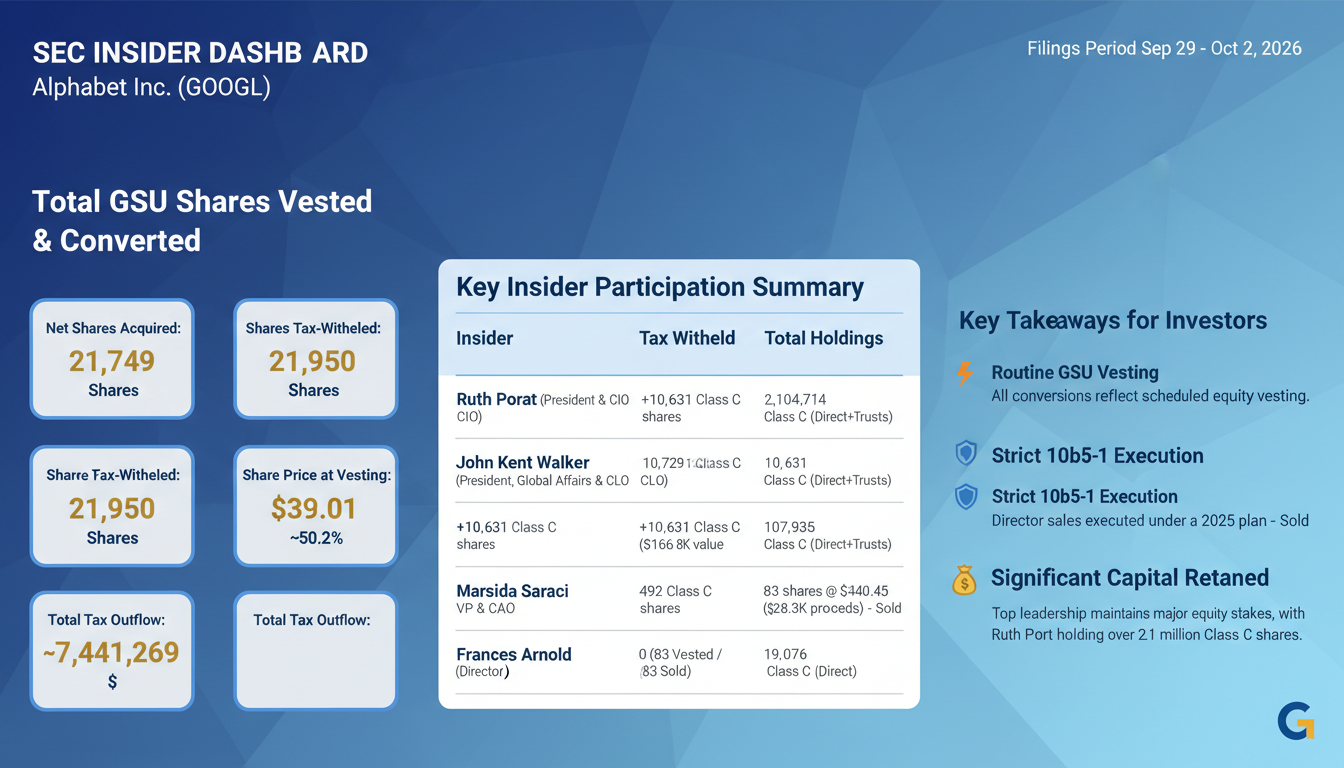

In [15]:
image_artifact = await artifact_service.load_artifact(
    app_name=APP_NAME,
    user_id=USER_ID,
    session_id=SESSION_ID,
    filename="sec_infographic.png"
)

if image_artifact and image_artifact.inline_data:
    display(Image(data=image_artifact.inline_data.data))
else:
    print("Infographic not found.")